# Import Library

In [1]:
import sys
import json
import math
import random
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))
from src.progressive_generator import (
    generate_partial_sketch,
    COMPLETION_LEVELS
)

from src.rasterizer import render_sketch
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "visualizations"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Setup success!")

Setup success!


# Load Dataset

In [2]:
TRAIN_SPLIT = PROJECT_ROOT / "data" / "splits" / "train.csv"

import pandas as pd
train_df = pd.read_csv(TRAIN_SPLIT)
print("Total training samples:", len(train_df))
train_df.head()

Total training samples: 3500


,drawing_id,key_id,category,recognized
0,bird_6277782474588160,6277782474588160,bird,True
1,car_6542125531398144,6542125531398144,car,True
2,fish_5727819831181312,5727819831181312,fish,True
3,airplane_4593425590517760,4593425590517760,airplane,True
4,house_6179516848275456,6179516848275456,house,True


# Create function to get real drawing

In [3]:
DATA_DIR = PROJECT_ROOT / "data" / "sampled"

def load_drawing(category, key_id):
    file_path = DATA_DIR / f"{category}.ndjson"
    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:
            if not line.strip():
                continue
            record = json.loads(line)
            if str(record.get("key_id")) == str(key_id):
                return record["drawing"]
    raise ValueError(
        f"Drawing {category}_{key_id} tidak ditemukan!"
    )

In [4]:
# take 1 sample category to try

category = "cat"
# Ambil satu gambar valid dari training dataset
sample = train_df[
    train_df["category"] == category
].sample(n=1, random_state=RANDOM_SEED).iloc[0]

# Ambil koordinat stroke asli
drawing = load_drawing(
    category=sample["category"],
    key_id=sample["key_id"]
)

print("Category:", sample["category"])
print("Drawing ID:", sample["drawing_id"])
print("Total strokes:", len(drawing))

Category: cat
Drawing ID: cat_5593442048540672
Total strokes: 7


# Visualization Comparison

In [10]:
def visualize_progressive_sketch(drawing, category, drawing_id):

    fig, axes = plt.subplots(
        1, 5,
        figsize=(20, 4)
    )
    for ax, percentage in zip(axes, COMPLETION_LEVELS):
        # Generate partial sketch
        partial_drawing = generate_partial_sketch(
            drawing,
            percentage
        )
        # Rasterize using original drawing as reference
        image = render_sketch(
            partial_drawing,
            image_size=224,
            reference_drawing=drawing
        )
        ax.imshow(image)
        ax.set_title(
            f"{percentage}%\n"
            f"{len(partial_drawing)}/{len(drawing)} strokes",
            fontsize=10
        )
        ax.axis("off")
    fig.suptitle(
        f"Pure Stroke-Based: {category} | {drawing_id}",
        fontsize=14
    )
    plt.tight_layout()
    output_path = (
        PROJECT_ROOT / "outputs" / "visualizations" /
        f"{drawing_id}_progressive.png"
    )
    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

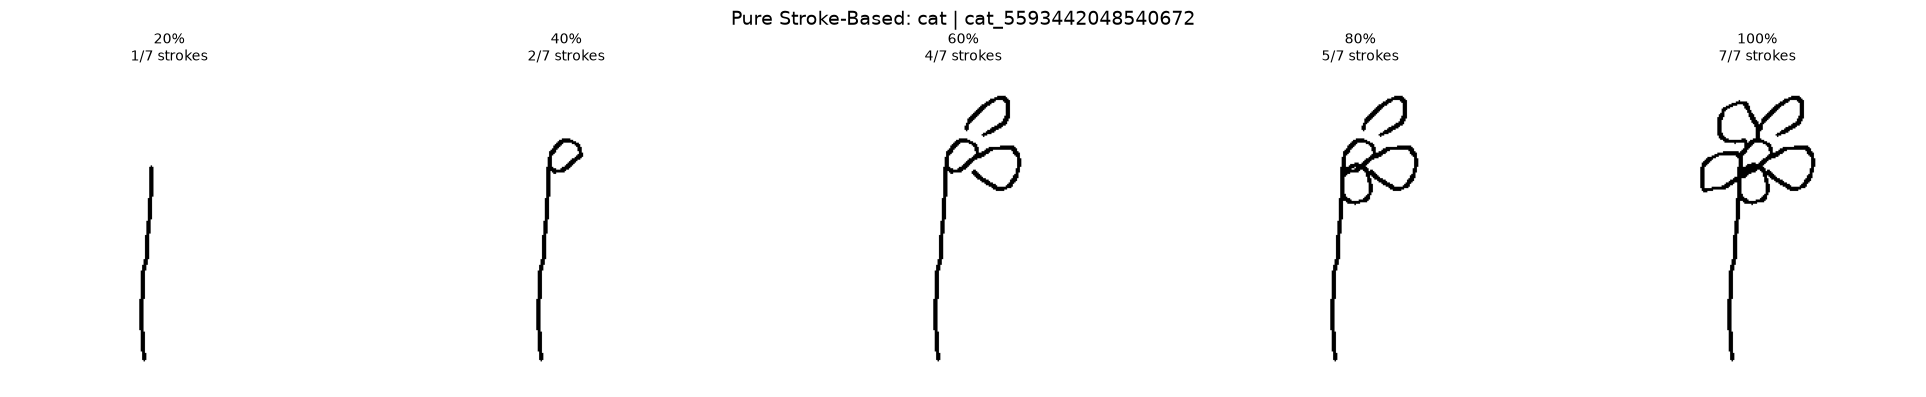

In [11]:
visualize_progressive_sketch(
    drawing=drawing,
    category=sample["category"],
    drawing_id=sample["drawing_id"]
)

# Try to some categories

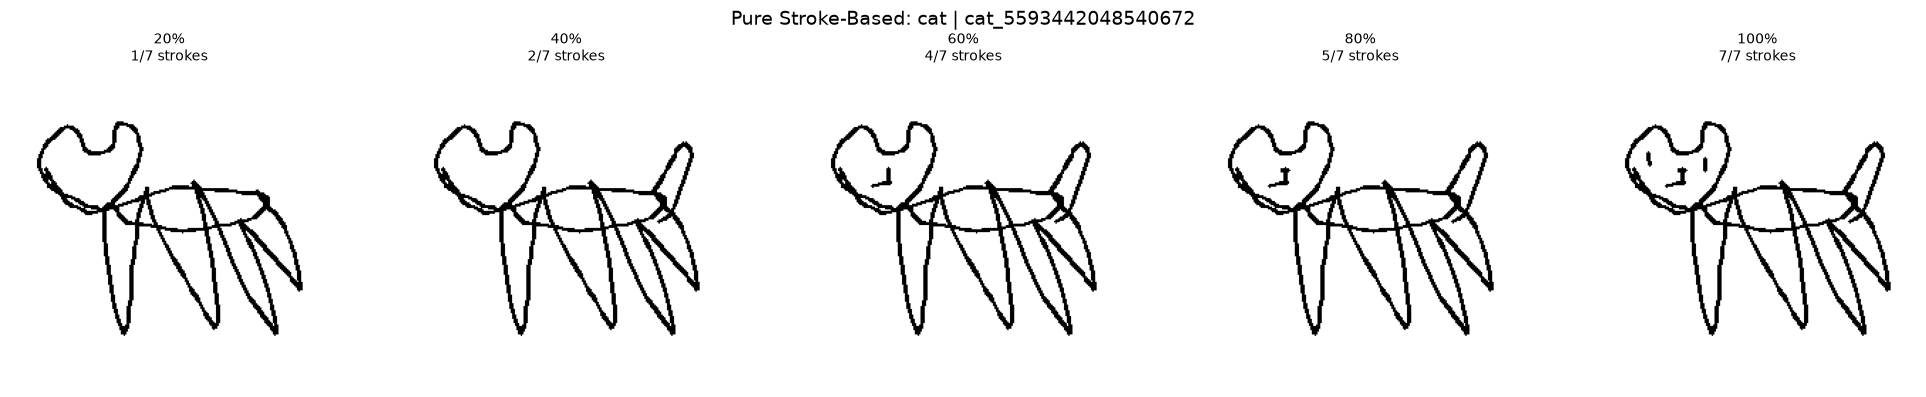

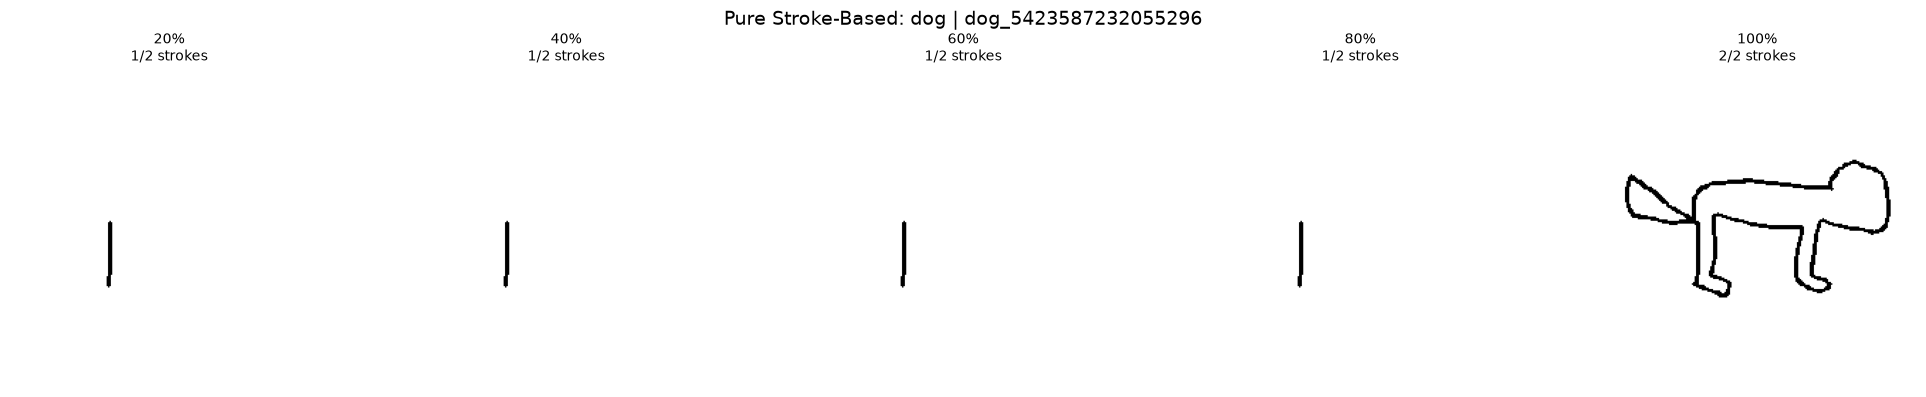

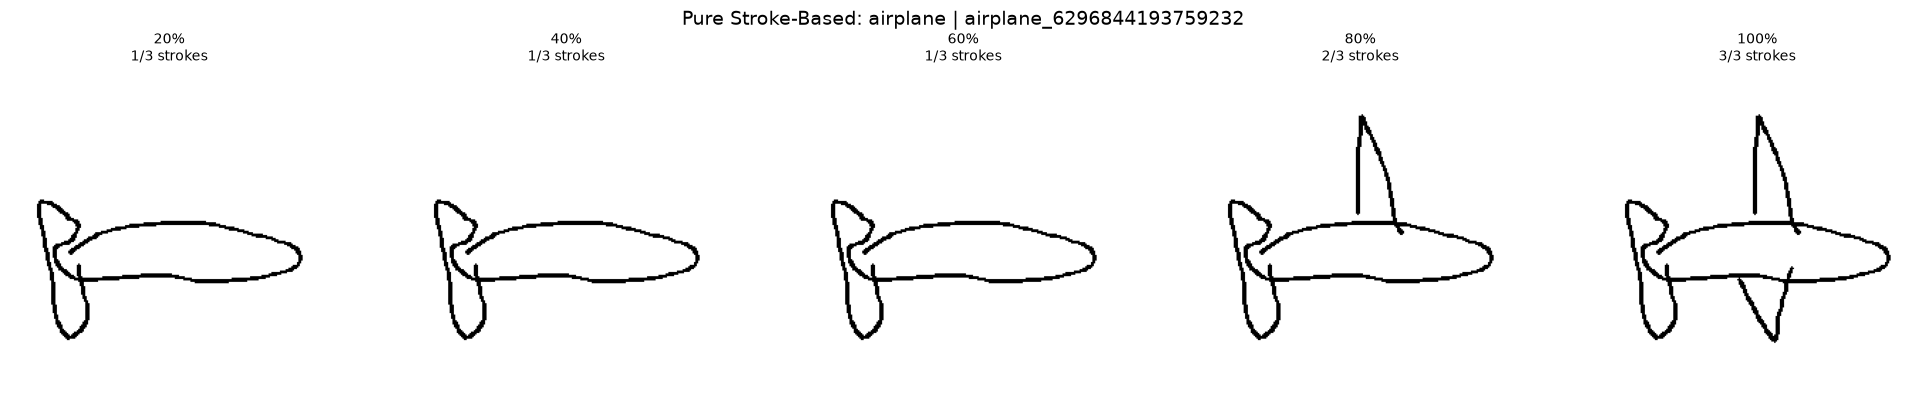

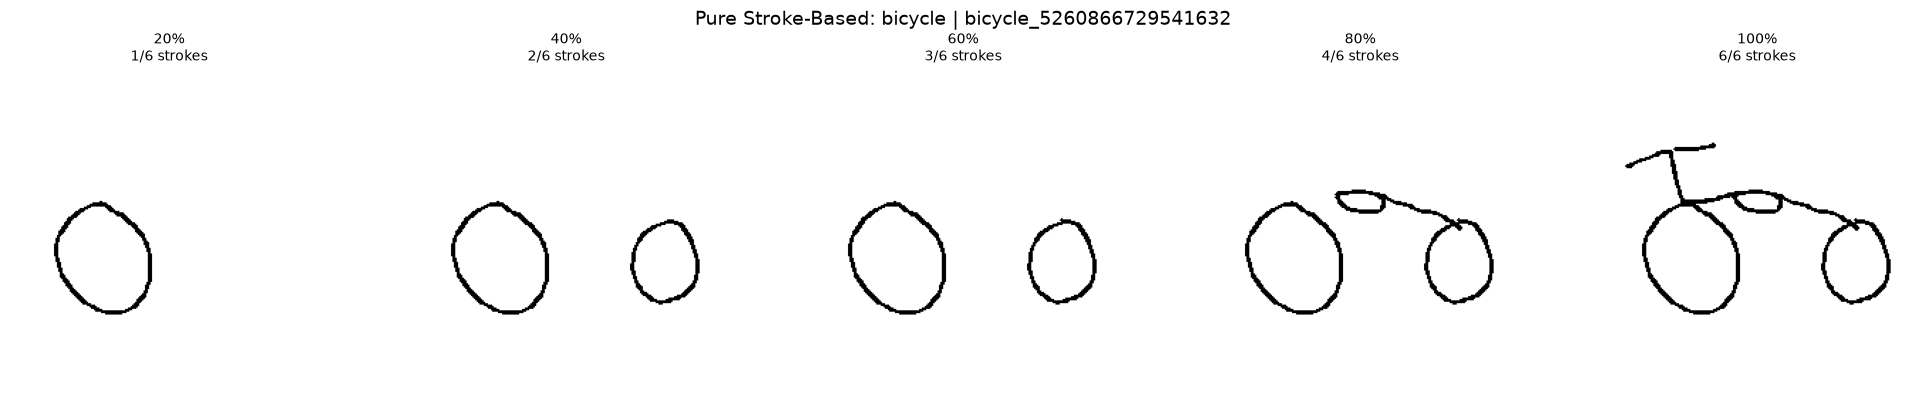

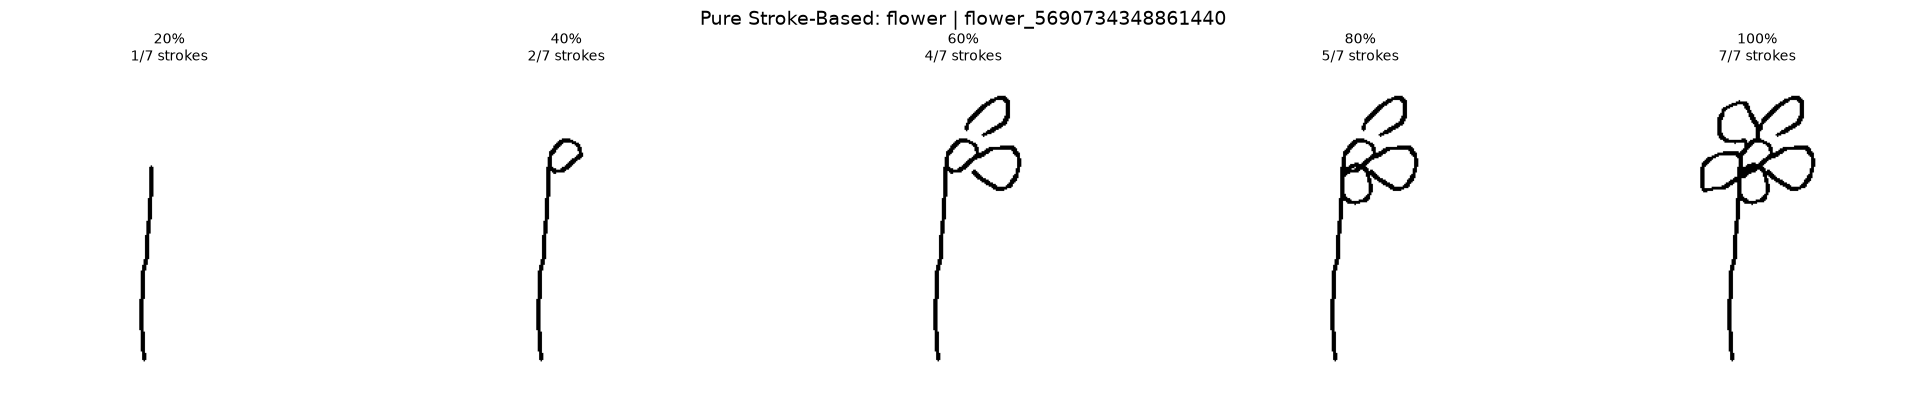

In [ ]:
sample_categories = [
    "cat",
    "dog",
    "airplane",
    "bicycle",
    "flower"
]

for category in sample_categories:
    category_sample = train_df[
        train_df["category"] == category
    ].sample(n=1, random_state=RANDOM_SEED).iloc[0]

    drawing = load_drawing(
        category=category_sample["category"],
        key_id=category_sample["key_id"]
    )

    visualize_progressive_sketch(
        drawing=drawing,
        category=category,
        drawing_id=category_sample["drawing_id"]
    )

In [9]:
for percentage in COMPLETION_LEVELS:
    partial = generate_partial_sketch(
        drawing,
        percentage
    )
    expected_strokes = max(
        1,
        int(len(drawing) * percentage / 100)
    )
    assert len(partial) == expected_strokes
    print(
        f"{percentage}%: "
        f"{len(partial)}/{len(drawing)} strokes"
    )
print("Pure Stroke-Based validation passed!")

20%: 1/7 strokes
40%: 2/7 strokes
60%: 4/7 strokes
80%: 5/7 strokes
100%: 7/7 strokes
Pure Stroke-Based validation passed!
